# Un core · dosis y volumen reconstruidos · X₀=0.20 g/L

**Cambio solicitado de condición inicial:** X0=0.20g/L únicamente en LAB016–018, tanto en caso nominal como reconstruido. Equivale a6.6667 millones de células viables/mL (redondeado6.67) con30pg/célula. Se usa0.20 exacto, no0.2001. LAB019–021 conservan0.2831619028/0.1533416694/0.1361529277g/L. Es una sensibilidad de inicialización, no una nueva medición. Los dos casos comparten esta nueva X0; «Anterior · pulso nominal» identifica las entradas nominales, no una curva que conserve X0=0.39.

Al cambiar X0 se recalculan las trayectorias, O₂, el estado del mosto retornado y las concentraciones del pulmón. Las masas externas y volúmenes se reconstruyen con el mismo protocolo. No se recalibra theta ni se alteran dosis, tiempos, composición inicial del agua o coeficientes de gas. Se reemplazan las conclusiones numéricas de la ejecución anterior.

Comparación: **Anterior · pulso nominal** del14 al100%, frente a **Reconstruido · mezcla y volumen**. theta_nv2, todos los parámetros, M original A=0.3/4h/12h, O₂ activo y liberación constante0.5870419885h⁻¹ quedan fijos; sin optimización. LAB019–021 permanecen idénticos. Sólo se reconstruye el accidente LAB016–018.

Datos del operador: pulmón500mL en agua; objetivo140mg/L YAN por reactor; caudales100mL/230s,235s,245s para016/017/018;140s de retorno017 simultáneo a alimentación016/018; después016/018 completan100mL y017 recibe200mL. Agua sin azúcar/etanol/biomasa al preparar. Se consideran2L justo antes del pulso y ningún otro muestreo retirado de016–018.

Convención para el objetivo140mg/L: receta calculada sobre2L previos, es decir280mg por100mL, pulmón inicial con2.8g/L YAN y1.4g totales. Si la receta real compensó el volumen añadido para obtener140mg/L final, esta concentración inicial debería ser5% mayor. No se calibra esa incertidumbre.

## Reconstrucción del pulmón

Se integra mezcla homogénea con los caudales calibrados: retorno017 durante0–140s; alimentación016 hasta230s y018 hasta245s; alimentación017 durante245–715s. El inicio245s para017 representa «después de terminar016/018». Durante el retorno entra la composición de mosto017 predicha justo antes de nutrir (incluido YAN residual), no agua.

Balances del pulmón para cada concentración C:
\(dV/dt=Q_{\rm retorno}-\sum Q_{\rm salida}\),
\(d(VC)/dt=Q_{\rm retorno}C_{017}-\sum Q_{\rm salida}C\).
Se computa el nutriente externo como trazador separado, sin contar el YAN retornado como nutriente nuevo. Se espera aproximadamente128/247/128mg/L expresados por2L,59.6mL retornados y159.6mL remanentes. El modelo predice el retorno de glucosa, fructosa, etanol y biomasa hacia el pulmón, y su posterior redistribución.

## Aplicación al modelo y aproximaciones

Se conserva la estructura de saltos del modelo original: la operación hidráulica de715s se colapsa en el horario nominal de cada pulso. Se ignoran reacción biológica y desgasificación en el pulmón durante esos minutos. La composición retornada se aproxima por la predicha pre-pulso; no se inventan mediciones. No se resuelve la cronología subhoraria ni se desplaza deliberadamente el pulso para ajustar CO₂.

Para016/018: \(C^+=(2C^-+m_{\rm entrada})/2.1\).
Para017: \(C^+=[(2-0.0595745)C^-+m_{\rm entrada}]/2.1404255\).
Esto se aplica a X,N,G,F,E y también a Cd/O₂. El pulmón inicialmente se supone sin Cd/O₂; no se introduce aireación nueva no medida. Puede ser una limitación para O₂ real del agua. Se comprueba conservación global incluyendo pulmón remanente.

M mantiene su fórmula y coeficientes originales, con dosis de nutriente externo entregado/2L como convención coherente con el protocolo previo; el salto químico usa masa y volumen explícitos, no añade esa dosis otra vez. No se utiliza q0 ni química sin nutrición. Después del salto se integra el mismo RHS cinético sin cambios.

El CSV de CO₂016–018 usaba referencia2L. Se recupera su caudal másico multiplicando por2L y se divide por el volumen reconstruido. Esa corrección de observación se aplica en memoria **a ambos casos**. La predicción anterior también se transforma de su caudal másico2L·q a ese mismo volumen; no se altera su producción ni su química. Se incluyen métricas con soporte común y una tabla de referencia antigua sin conversión para documentar la conversión de unidades con la nueva X0. LAB019–021 no se reconvierten.

Figuras por pares con muestras: CO₂ completo/pico/cola, más una vista adicional por2L de referencia para conservar exactamente la presentación previa; X,YAN,E,G,F,G+F, volumen y Cd. Todas las muestras químicas numéricas se incluyen;016–018 G+F por densidad y biomasa experimental. Los roles son previos, no nuevos ajustes. Sin CSV/PNG de resultados ni cambios en datos/modelos/ajustes originales.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation.models.historical import co2 as gas,kinetics
from wine_fermentation.models.historical.calibration import load,release_forward,Search
from wine_fermentation.comparison import observations
NAME='15_single_core_reconstructed_dose_volume'
protected=[p for folder in ('src','configs','data','notebooks','results') for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and not p.name.startswith(NAME+'.')]
before={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
old=__import__('nbformat').read(ROOT/'notebooks/diagnostics/09_historical_single_core.executed.ipynb',4)
stream=''.join(o.get('text','') for o in old.cells[4].outputs if o.output_type=='stream')
records=json.JSONDecoder().raw_decode(stream.split('PARAMETROS_COMPLETOS_SIN_EXPORTACION\n')[1])[0]
p0=next(r['parametros'] for r in records if r['caso']=='Propuesta · un core, sin O₂' and r['etapa']=='E1')
assert p0['A']==.3
theta=kinetics.normalize_parameters(json.loads((ROOT/'configs/theta/theta_nv2.json').read_text()))
theta_before=theta.copy();assert 0<theta['Yeg']<=.5114 and 0<theta['Yef']<=.5114
v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018']
batches=dict(v.batches);b=batches['LAB017'];events=b.pulses['N'];assert np.isclose(sum(d for t,d in events),.28)
batches['LAB017']=replace(b,pulses={**b.pulses,'N':((min(t for t,d in events),.28),)})
# Override only the requested initial biomass, in memory.
initials_before={lab:dict(b.initials) for lab,b in batches.items()}
X0_REQUESTED=0.20
for lab in ['LAB016','LAB017','LAB018']:
 batches[lab]=replace(batches[lab],initials={**batches[lab].initials,'X':X0_REQUESTED})
for lab,b in batches.items():
 expected={**initials_before[lab],'X':X0_REQUESTED} if lab in ['LAB016','LAB017','LAB018'] else initials_before[lab]
 assert b.initials==expected
 if lab in ['LAB019','LAB020','LAB021']:assert b.initials==initials_before[lab]
print('X0 LAB016–018=0.20g/L; células viables:',X0_REQUESTED/.03,'millones/mL.')
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','co2_raw_g_l_h'])
obs=observations(raw);support={lab:obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy() for lab in LABS}
contexts={};calls=0
for lab,b in batches.items():
 f=gas.integrate_core(b,theta,b.time);calls+=1
 consumed=(f.G+f.F).iloc[0]-(f.G+f.F).to_numpy();z=np.clip((consumed-2.)/8.,0,1)
 contexts[lab]=dict(time=f.index.to_numpy(),dt=np.diff(f.index),gate=z*z*(3-2*z),q=gas.production(theta,b,f),
  sat_base=gas.csat(b,f,{'CO2sat_scale':1.}),events=b.pulses['N'],core=f)
assert calls==6 and all('q0' not in x and 'core0' not in x for x in contexts.values())
display(pd.Series(theta,name='theta_nv2 congelado'))
display(pd.Series(p0,name='Coeficientes heredados E1; configuración efectiva en la celda siguiente'))
windows={}
for lab in LABS:
 pulse=batches[lab].pulses['N'][0][0];end=v.horizons[lab]
 windows[lab]={'Registro':(0,end),'Arranque':(0,pulse),'Pico posterior':(pulse,min(pulse+24,end)),'Cola tardía':(pulse+32,end)}
display(pd.DataFrame([dict(LAB=lab,eventos=batches[lab].pulses['N'],corte=v.horizons[lab],**batches[lab].initials) for lab in LABS]))
display(pd.DataFrame([dict(LAB=lab,tramo=w,inicio=ab[0],fin=ab[1]) for lab,ww in windows.items() for w,ab in ww.items()]))

from wine_fermentation.data import natural_batches
_,training,_=natural_batches(ROOT)
display(pd.DataFrame([dict(LAB=b.batch,eventos_N=b.pulses['N']) for b in training]))


X0 LAB016–018=0.20g/L; células viables: 6.666666666666667 millones/mL.


mu0         0.082780
betaG0      0.412766
betaF0      0.447244
Kn0         0.008996
Kg0         4.400775
Kf0        19.296084
Kig0      122.553899
Kie0      286.579410
Kd0         0.000228
Yxn         5.179898
Yxg         0.966094
Yxf         1.109896
Yeg         0.482075
Yef         0.483728
m0          0.018339
Name: theta_nv2 congelado, dtype: float64

kCO2_release_h                            2.348168
CO2sat_scale                                   2.5
O2_qmax_mg_gdw_h                              0.15
O2_initial_scale                            0.1954
pulse_t_rise_h                           64.658704
pulse_activity_gain                           0.25
chem_activation_start_fraction            0.735057
chem_activation_duration_fraction          1.06391
matrix_gain                               0.774287
A                                              0.3
tau_rise_h                                     4.0
tau_decay_h                                   12.0
N_ref_g_l                                     0.14
kernel_normalization                 analytic_peak
activation_start_g_l                           2.0
activation_width_g_l                           8.0
Name: Coeficientes heredados E1; configuración efectiva en la celda siguiente, dtype: object

,LAB,eventos,corte,X,N,G,F,E
0,LAB019,"((64.33333333333277, 0.08),)",166.000000,0.283162,0.230025,79.190000,78.970000,12.075372
1,LAB020,"((71.66666666666694, 0.08),)",172.333333,0.153342,0.225556,77.940000,79.520000,11.917524
2,LAB021,"((47.5, 0.08),)",166.000000,0.136153,0.231202,80.190000,81.040000,11.759676
3,LAB016,"((56.93555555555583, 0.14),)",151.100000,0.200000,0.214330,84.158815,88.341185,0.000000
4,LAB017,"((56.933611111110835, 0.28),)",141.000000,0.200000,0.214330,84.158815,88.341185,0.000000
5,LAB018,"((56.93166666666694, 0.14),)",141.000000,0.200000,0.214330,84.158815,88.341185,0.000000


,LAB,tramo,inicio,fin
0,LAB019,Registro,0.000000,166.000000
1,LAB019,Arranque,0.000000,64.333333
2,LAB019,Pico posterior,64.333333,88.333333
3,LAB019,Cola tardía,96.333333,166.000000
4,LAB020,Registro,0.000000,172.333333
5,LAB020,Arranque,0.000000,71.666667
6,LAB020,Pico posterior,71.666667,95.666667
7,LAB020,Cola tardía,103.666667,172.333333
8,LAB021,Registro,0.000000,166.000000
9,LAB021,Arranque,0.000000,47.500000


,LAB,eventos_N
0,LAB004,"((68.5, 0.08),)"
1,LAB005,"((68.5, 0.08),)"
2,LAB006,"((100.0, 0.08),)"
3,LAB007,"((65.5, 0.08),)"
4,LAB008,"((65.5, 0.08),)"
5,LAB009,"((41.84615384615385, 0.08),)"


In [2]:
from scipy.integrate import solve_ivp
from wine_fermentation.comparison import chemical_observations,CHEMICAL_COLUMNS
base={**p0,'kCO2_release_h':p0['kCO2_release_h']/4,'A':.3}
CASES=['Anterior · pulso nominal','Reconstruido · mezcla y volumen']
COLORS={CASES[0]:'#0072B2',CASES[1]:'#009E73'}
def oxygen_curve(b,f,initial=None):
 t=f.index.to_numpy();O=np.zeros(len(t));ini=b.initials
 O[0]=base['O2_initial_scale']*gas.o2_saturation_mg_l(b.temperature_c[0],ini['E'],ini['G'],ini['F']) if initial is None else initial
 for i,dt in enumerate(np.diff(t)):
  O[i+1]=max(O[i]-dt*base['O2_qmax_mg_gdw_h']*f.X.iloc[i]*O[i]/(.25+O[i]),0.)
 return O
def source_arrays(b,f,events,O):
 t=f.index.to_numpy();consumed=(f.G+f.F).iloc[0]-(f.G+f.F).to_numpy()
 z=np.clip((consumed-2)/8,0,1)
 # For post-pulse segments the initial sugar reference remains the actual original initial.
 if t[0]>0:
  z=np.clip((b.initials['G']+b.initials['F']-(f.G+f.F).to_numpy()-2)/8,0,1)
 r,M=Search.histories(t,events,base);a=1+(base['pulse_activity_gain']-1)*r
 ff=.08+.92*.75**2/(.75**2+O**2)
 return z*z*(3-2*z)*a*M*ff*gas.production(theta,b,f),gas.csat(b,f,{'CO2sat_scale':1.})
chemistry={};gascurves={};old_O={};checks=[]
for lab in LABS:
 b=batches[lab];f=contexts[lab]['core'].copy();f['GF']=f.G+f.F
 O=oxygen_curve(b,f);src,sat=source_arrays(b,f,b.pulses['N'],O)
 pred,cd,qout=release_forward(dict(source=src,dt=np.diff(f.index),sat_base=sat),base)
 chemistry[CASES[0],lab]=f;old_O[lab]=O
 gascurves[CASES[0],lab]=pd.DataFrame(dict(qpred=pred,Cd=cd,qgas=qout,qprod=src),index=f.index)
assert theta==theta_before
# Reservoir hydraulics in liters/seconds; C vector includes chemistry,Cd,O2 and external-N tracer.
GROUP=['LAB016','LAB017','LAB018']
pre={};tp={}
for lab in GROUP:
 tp[lab]=batches[lab].pulses['N'][0][0]
 f=chemistry[CASES[0],lab]
 assert tp[lab] in f.index
 pre[lab]=f.loc[tp[lab],['X','N','G','F','E']].to_numpy(float)
p17=pre['LAB017']
ret=np.r_[p17,np.interp(tp['LAB017'],gascurves[CASES[0],'LAB017'].index,gascurves[CASES[0],'LAB017'].Cd),
 np.interp(tp['LAB017'],chemistry[CASES[0],'LAB017'].index,old_O['LAB017']),0.]
stock0=np.array([0.,2.8,0.,0.,0.,0.,0.,2.8])
# state [stock volume, concentrations8, delivered masses(3x8)]
y=np.r_[.5,stock0,np.zeros(24)]
q=np.array([.1/230,.1/235,.1/245])
for a,b in [(0.,140.),(140.,230.),(230.,245.),(245.,715.)]:
 mid=(a+b)/2;qr=q[1] if mid<140 else 0.
 qo=np.array([q[0] if mid<230 else 0.,q[1] if mid>=245 else 0.,q[2] if mid<245 else 0.])
 def hyd(t,y):
  V=y[0];C=y[1:9]
  return np.r_[qr-qo.sum(),qr/V*(ret-C),(qo[:,None]*C).ravel()]
 sol=solve_ivp(hyd,(a,b),y,rtol=1e-11,atol=1e-12)
 assert sol.success
 y=sol.y[:,-1]
delivery=y[9:].reshape(3,8);removed=.1/235*140
Vnew={'LAB016':2.1,'LAB017':2-removed+.2,'LAB018':2.1}
Vretained=np.array([2.,2-removed,2.])
post={};audit=[]
for j,lab in enumerate(GROUP):
 reactor_before=np.r_[pre[lab],np.interp(tp[lab],gascurves[CASES[0],lab].index,gascurves[CASES[0],lab].Cd),
  np.interp(tp[lab],chemistry[CASES[0],lab].index,old_O[lab])]
 after=(Vretained[j]*reactor_before+delivery[j,:7])/Vnew[lab];post[lab]=after
 audit.append(dict(LAB=lab,volumen_antes_L=2,retorno_L=removed if lab=='LAB017' else 0,
  entrada_L=.2 if lab=='LAB017' else .1,volumen_despues_L=Vnew[lab],
  YAN_entrada_mg=delivery[j,1]*1000,YAN_externo_mg=delivery[j,7]*1000,
  dosis_M_mg_L=delivery[j,7]/2*1000,N_pre_mg_L=pre[lab][1]*1000,N_post_mg_L=after[1]*1000))
 # Chemical trajectory: same pre-pulse, conservative mixed jump, unchanged kinetic RHS after it.
 oldf=chemistry[CASES[0],lab];tout=oldf.index[oldf.index>=tp[lab]].to_numpy()
 sol=solve_ivp(lambda t,x:kinetics.rhs(t,x,theta,batches[lab]),(tp[lab],float(tout[-1])),after[:5],
  t_eval=tout,method='LSODA',rtol=2e-9,atol=2e-11,max_step=.5)
 assert sol.success
 fpost=pd.DataFrame(np.maximum(sol.y.T,0),index=tout,columns=kinetics.STATE_NAMES);fpost['GF']=fpost.G+fpost.F
 f=pd.concat([oldf.loc[oldf.index<tp[lab]],fpost]);chemistry[CASES[1],lab]=f
 Opost=oxygen_curve(batches[lab],fpost,after[6])
 events=((tp[lab],delivery[j,7]/2),)
 src,sat=source_arrays(batches[lab],fpost,events,Opost)
 cd=np.zeros(len(tout));cd[0]=after[5];qout=np.zeros(len(tout))
 qout[0]=gas.release(cd[0],sat[0]*base['CO2sat_scale'],base)
 for i,dt in enumerate(np.diff(tout),1):
  inv=cd[i-1]+dt*src[i-1];s=sat[i]*base['CO2sat_scale'];k=base['kCO2_release_h']
  aa=1+dt*k;bb=s*(1+.05*dt*k)-inv;rr=np.sqrt(bb*bb+4*aa*inv*s)
  cd[i]=2*inv*s/(rr+bb) if bb>=0 else (rr-bb)/(2*aa)
  qout[i]=(inv-cd[i])/dt
 assert np.max(abs(np.diff(cd)-np.diff(tout)*(src[:-1]-qout[1:])))<1e-9
 newpost=pd.DataFrame(dict(qpred=base['matrix_gain']*qout,Cd=cd,qgas=qout,qprod=src),index=tout)
 oldg=gascurves[CASES[0],lab]
 gascurves[CASES[1],lab]=pd.concat([oldg.loc[oldg.index<tp[lab]],newpost])
 assert cd.min()>=0 and qout.min()>-1e-12
# Global mixing conservation includes unconsumed reservoir; reactions are not applied during collapsed mixing.
initial=np.sum(np.vstack([np.r_[pre[l],np.interp(tp[l],gascurves[CASES[0],l].index,gascurves[CASES[0],l].Cd),
 np.interp(tp[l],chemistry[CASES[0],l].index,old_O[l])] for l in GROUP])*2,axis=0)+.5*stock0[:7]
final=np.sum(np.vstack([post[l]*Vnew[l] for l in GROUP]),axis=0)+y[0]*y[1:8]
np.testing.assert_allclose(initial,final,atol=1e-9,rtol=1e-9)
assert np.isclose(y[0],.159574468085106,atol=1e-9)
for lab in LABS[:3]:
 chemistry[CASES[1],lab]=chemistry[CASES[0],lab].copy()
 gascurves[CASES[1],lab]=gascurves[CASES[0],lab].copy()
display(pd.DataFrame(audit))
display(pd.DataFrame([dict(estado=k,masa_inicial=initial[i],masa_final=final[i],error=final[i]-initial[i]) for i,k in enumerate(['X','N','G','F','E','Cd','O2'])]))
print('Pulmón remanente L:',y[0],'concentraciones finales:',y[1:9])
display(pd.Series(base,name='Todos los coeficientes congelados'))


,LAB,volumen_antes_L,retorno_L,entrada_L,volumen_despues_L,YAN_entrada_mg,YAN_externo_mg,dosis_M_mg_L,N_pre_mg_L,N_post_mg_L
0,LAB016,2,0.000000,0.1,2.100000,256.815223,256.815223,128.407611,1.000581e-07,122.292963
1,LAB017,2,0.059574,0.2,2.140426,493.355505,493.355505,246.677752,1.944467e-07,230.494123
2,LAB018,2,0.000000,0.1,2.100000,256.194561,256.194561,128.097281,1.330926e-07,121.997410


,estado,masa_inicial,masa_final,error
0,X,7.861246e+00,7.861246e+00,0.000000e+00
1,N,1.400000e+00,1.400000e+00,-2.220446e-16
2,G,3.009625e+02,3.009625e+02,5.684342e-14
3,F,4.049005e+02,4.049005e+02,0.000000e+00
4,E,1.503355e+02,1.503355e+02,0.000000e+00
5,Cd,1.598515e+01,1.598515e+01,0.000000e+00
6,O2,4.227543e-09,4.227543e-09,8.271806e-25


Pulmón remanente L: 0.15957446808510628 concentraciones finales: [1.55925220e-01 2.46677752e+00 5.99203129e+00 8.04630427e+00
 2.96391918e+00 3.17068747e-01 1.00107040e-10 2.46677752e+00]


kCO2_release_h                            0.587042
CO2sat_scale                                   2.5
O2_qmax_mg_gdw_h                              0.15
O2_initial_scale                            0.1954
pulse_t_rise_h                           64.658704
pulse_activity_gain                           0.25
chem_activation_start_fraction            0.735057
chem_activation_duration_fraction          1.06391
matrix_gain                               0.774287
A                                              0.3
tau_rise_h                                     4.0
tau_decay_h                                   12.0
N_ref_g_l                                     0.14
kernel_normalization                 analytic_peak
activation_start_g_l                           2.0
activation_width_g_l                           8.0
Name: Todos los coeficientes congelados, dtype: object

In [3]:
def volume(lab,t):
 t=np.asarray(t,float)
 return np.where(t>=tp[lab],Vnew[lab],2.) if lab in GROUP else np.ones_like(t)*2.
def factor(lab,t):return 2/volume(lab,t) if lab in GROUP else np.ones_like(np.asarray(t,float))
observed_common={lab:o.assign(y_common=o.co2_raw_g_l_h.to_numpy()*factor(lab,o.time_h)) for lab,o in support.items()}
def gas_values(case,lab,t,f):
 # Baseline originally predicts gas/L at model volume2L; reconstructed predicts at actual volume.
 return f.qpred.to_numpy()*factor(lab,t) if case==CASES[0] else f.qpred.to_numpy()
rows=[];legacy=[]
for case in CASES:
 for lab in LABS:
  f=gascurves[case,lab];pred=gas_values(case,lab,f.index,f);o=observed_common[lab]
  for window in ['Registro','Pico posterior','Cola tardía']:
   start,end=windows[lab][window];z=o.loc[o.time_h.between(start,end)]
   yy=z.y_common.to_numpy();yp=np.interp(z.time_h,f.index,pred);e=yp-yy
   rows.append(dict(caso=case,LAB=lab,rol='Calibración previa' if lab in LABS[:3] else 'Holdout previo',
    tramo=window,n=len(z),RMSE=np.sqrt(np.mean(e*e)),sesgo=e.mean(),pico_predicho=yp.max(),pico_medido=yy.max(),
    hora_pico_predicho=float(z.time_h.iloc[np.argmax(yp)]),hora_pico_medida=float(z.time_h.iloc[np.argmax(yy)])))
  if case==CASES[0]:
   z=support[lab];e=np.interp(z.time_h,f.index,f.qpred)-z.co2_raw_g_l_h
   legacy.append(dict(LAB=lab,RMSE_previo=float(np.sqrt(np.mean(e*e)))))
metrics=pd.DataFrame(rows)
legacy=pd.DataFrame(legacy)
# LAB019–021 must reproduce the previous execution, independent of the new X0 in016–018.
assert np.isclose(legacy.loc[legacy.LAB.isin(LABS[:3]),'RMSE_previo'].mean(),.1280027902,atol=1e-8)
display(legacy);display(metrics.round(6))
display(metrics.groupby(['tramo','rol','caso']).RMSE.mean().unstack('caso').round(6))
CHEM=[('E','Etanol',1,'g/L'),('G','Glucosa',1,'g/L'),('F','Fructosa',1,'g/L'),('GF','Glucosa + fructosa',1,'g/L'),('X','Biomasa viable',1,'g/L'),('N','YAN',1000,'mg/L')]
def samples(lab,key):
 if lab in LABS[:3]:
  z=chemical_observations(v.chem,lab,key);return z.t_h.to_numpy(),z[CHEMICAL_COLUMNS[key]].to_numpy(),'Muestras experimentales'
 if key=='GF':
  z=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l']);return z.t_h.to_numpy(),2.5*(z.density_g_l.to_numpy()-1000),'G+F por densidad'
 if key=='X':
  z=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']);return z.t_h.to_numpy(),z.X_viable_g_l.to_numpy(),'Biomasa experimental'
 return np.array([]),np.array([]),'Sin muestras disponibles'
chemrows=[];counts=[]
for case in CASES:
 for lab in LABS:
  f=chemistry[case,lab]
  for key,title,scale,unit in CHEM:
   t,z,label=samples(lab,key);m=(t>0)&(t<=f.index[-1])
   if case==CASES[0]:counts.append(dict(LAB=lab,variable=title,n=len(t),origen=label))
   if m.any():
    e=(np.interp(t[m],f.index,f[key])-z[m])*scale
    chemrows.append(dict(caso=case,LAB=lab,variable=title,n=int(m.sum()),RMSE=np.sqrt(np.mean(e*e)),unidad=unit))
display(pd.DataFrame(counts));display(pd.DataFrame(chemrows).round(6))


,LAB,RMSE_previo
0,LAB019,0.128752
1,LAB020,0.044720
2,LAB021,0.210536
3,LAB016,0.121341
4,LAB017,0.179044
5,LAB018,0.140963


,caso,LAB,rol,tramo,n,RMSE,sesgo,pico_predicho,pico_medido,hora_pico_predicho,hora_pico_medida
0,Anterior · pulso nominal,LAB019,Calibración previa,Registro,166,0.128752,0.017958,0.686483,0.758905,73.500000,96.500556
1,Anterior · pulso nominal,LAB019,Calibración previa,Pico posterior,24,0.064550,0.030349,0.686483,0.733140,73.500000,72.507222
2,Anterior · pulso nominal,LAB019,Calibración previa,Cola tardía,70,0.128455,-0.070198,0.384490,0.758905,96.500556,96.500556
3,Anterior · pulso nominal,LAB020,Calibración previa,Registro,172,0.044720,0.004443,0.607719,0.597467,82.499167,79.500278
4,Anterior · pulso nominal,LAB020,Calibración previa,Pico posterior,24,0.046722,0.034093,0.607719,0.597467,82.499167,79.500278
5,Anterior · pulso nominal,LAB020,Calibración previa,Cola tardía,68,0.045578,-0.001022,0.384242,0.379666,104.499722,104.499722
6,Anterior · pulso nominal,LAB021,Calibración previa,Registro,166,0.210536,-0.027663,0.715257,1.087220,57.500278,52.500000
7,Anterior · pulso nominal,LAB021,Calibración previa,Pico posterior,25,0.255918,-0.199883,0.715257,1.087220,57.500278,52.500000
8,Anterior · pulso nominal,LAB021,Calibración previa,Cola tardía,87,0.119268,0.094102,0.423215,0.199496,79.500278,80.500417
9,Anterior · pulso nominal,LAB016,Holdout previo,Registro,152,0.118303,-0.010198,0.804034,0.798634,68.501667,46.499167


caso                               Anterior · pulso nominal  \
tramo          rol                                            
Cola tardía    Calibración previa                  0.097767   
               Holdout previo                      0.050257   
Pico posterior Calibración previa                  0.122397   
               Holdout previo                      0.195200   
Registro       Calibración previa                  0.128003   
               Holdout previo                      0.143358   

caso                               Reconstruido · mezcla y volumen  
tramo          rol                                                  
Cola tardía    Calibración previa                         0.097767  
               Holdout previo                             0.045988  
Pico posterior Calibración previa                         0.122397  
               Holdout previo                             0.165350  
Registro       Calibración previa                         0.128003  
               Holdout previo                             0.134295

,LAB,variable,n,origen
0,LAB019,Etanol,6,Muestras experimentales
1,LAB019,Glucosa,8,Muestras experimentales
2,LAB019,Fructosa,8,Muestras experimentales
3,LAB019,Glucosa + fructosa,12,Muestras experimentales
4,LAB019,Biomasa viable,11,Muestras experimentales
5,LAB019,YAN,13,Muestras experimentales
6,LAB020,Etanol,6,Muestras experimentales
7,LAB020,Glucosa,7,Muestras experimentales
8,LAB020,Fructosa,7,Muestras experimentales
9,LAB020,Glucosa + fructosa,12,Muestras experimentales


,caso,LAB,variable,n,RMSE,unidad
0,Anterior · pulso nominal,LAB019,Etanol,5,11.790213,g/L
1,Anterior · pulso nominal,LAB019,Glucosa,7,2.599255,g/L
2,Anterior · pulso nominal,LAB019,Fructosa,7,3.519361,g/L
3,Anterior · pulso nominal,LAB019,Glucosa + fructosa,11,5.859407,g/L
4,Anterior · pulso nominal,LAB019,Biomasa viable,10,0.333142,g/L
5,Anterior · pulso nominal,LAB019,YAN,12,44.020632,mg/L
6,Anterior · pulso nominal,LAB020,Etanol,5,4.005146,g/L
7,Anterior · pulso nominal,LAB020,Glucosa,6,8.833357,g/L
8,Anterior · pulso nominal,LAB020,Fructosa,6,5.428427,g/L
9,Anterior · pulso nominal,LAB020,Glucosa + fructosa,11,9.518108,g/L


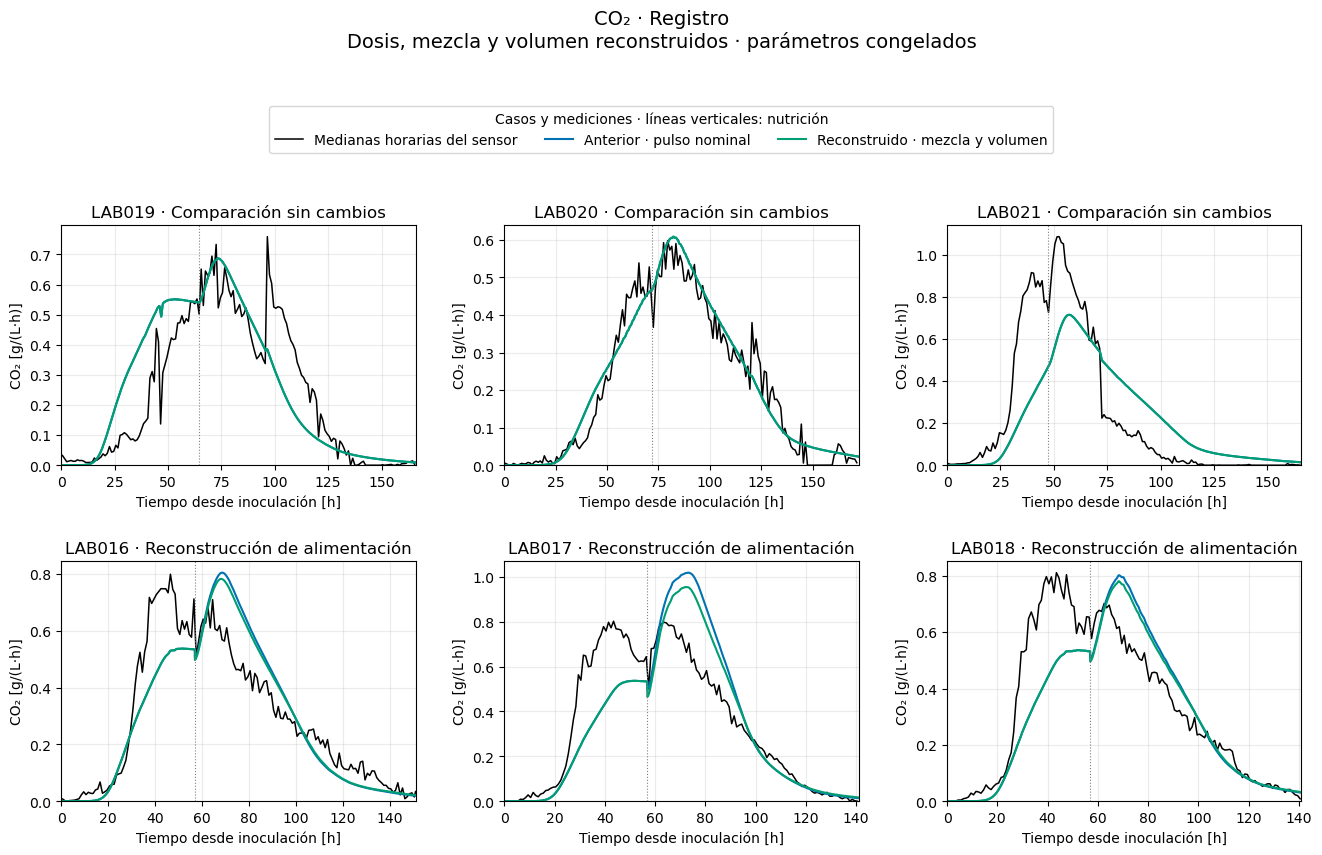

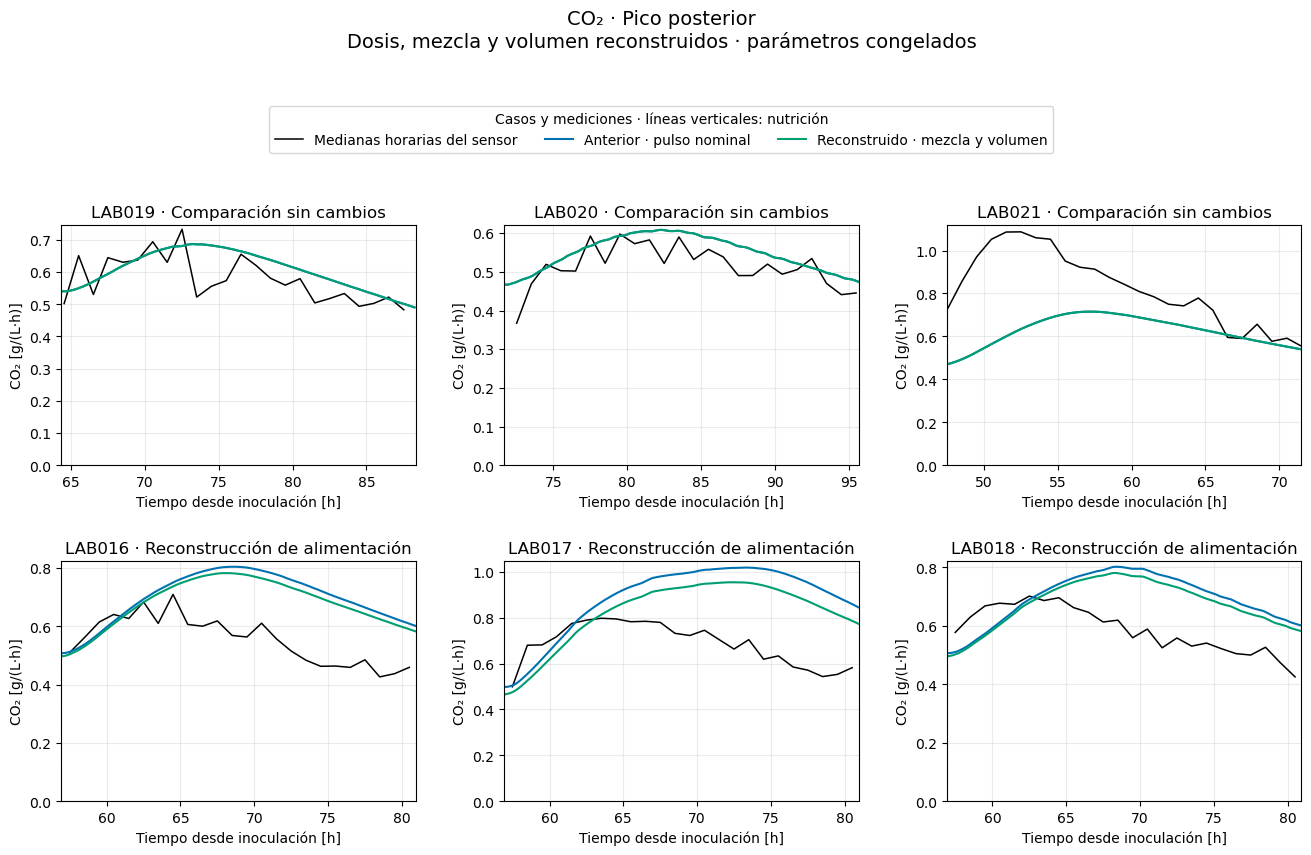

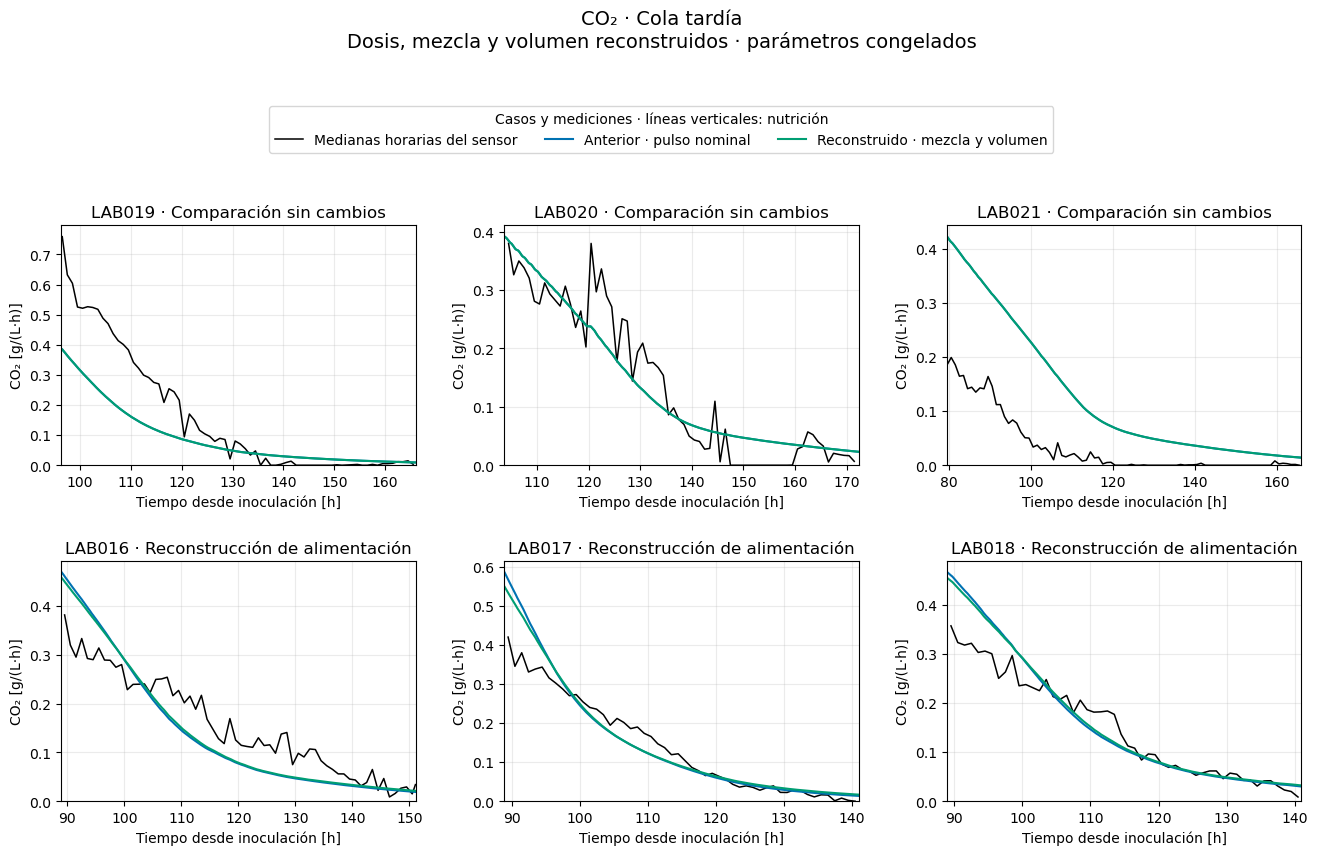

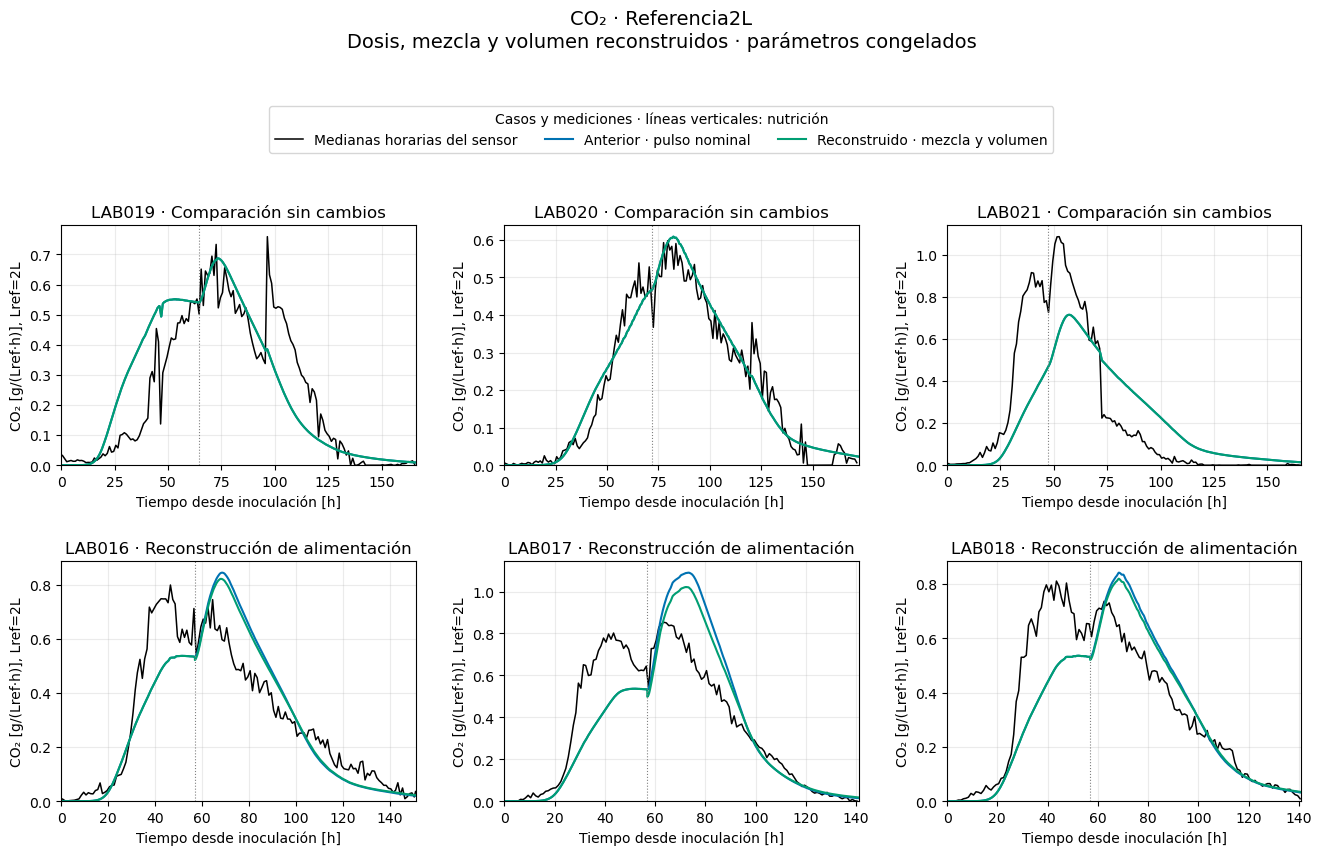

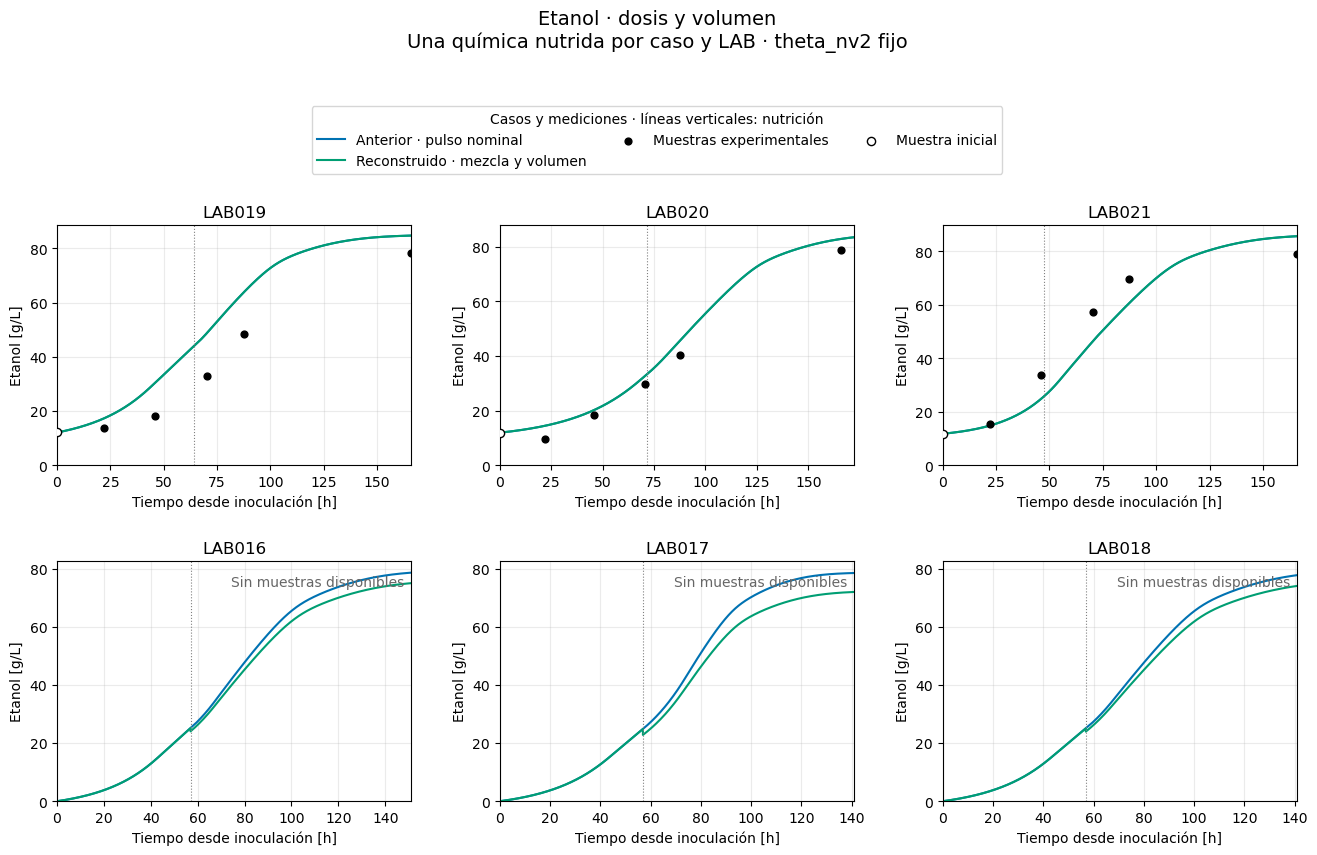

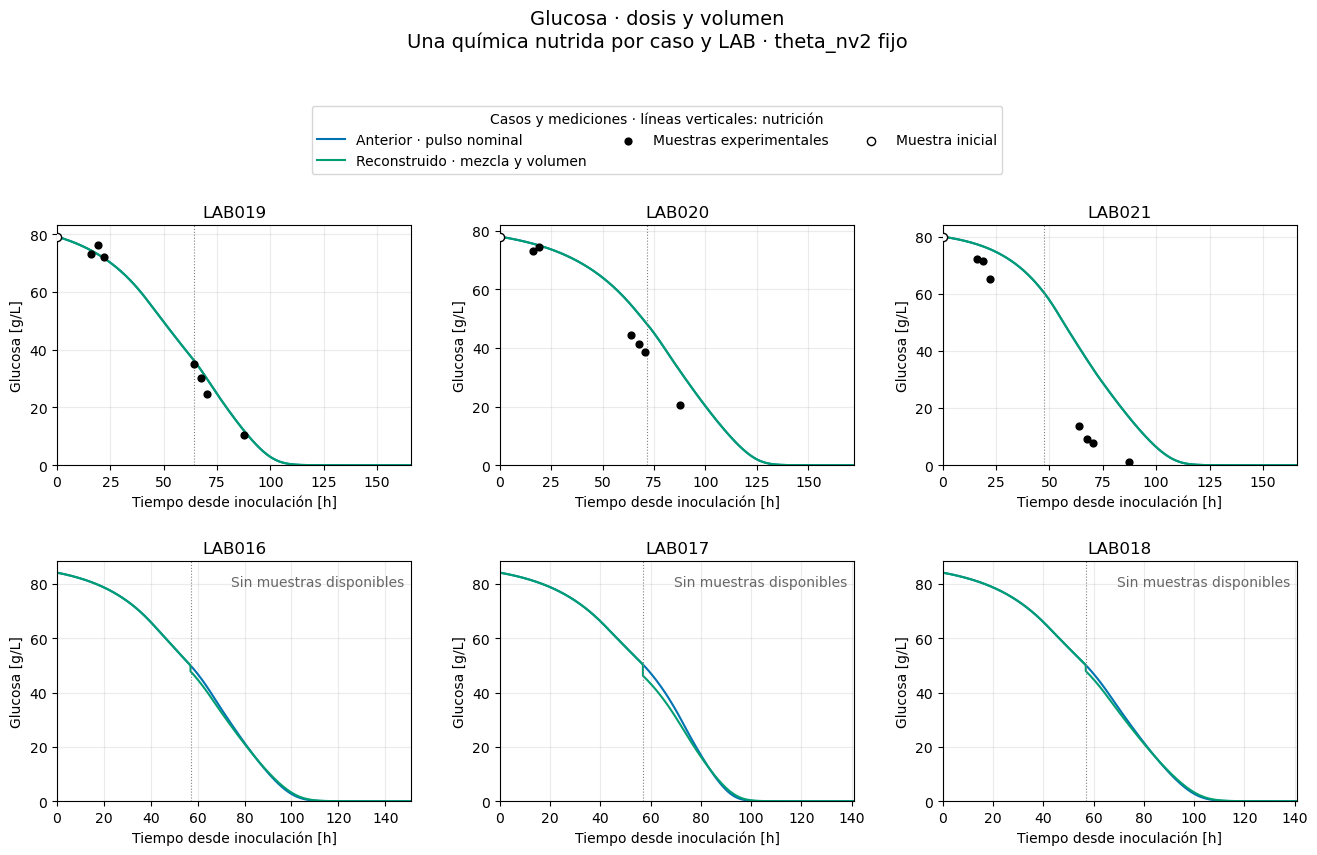

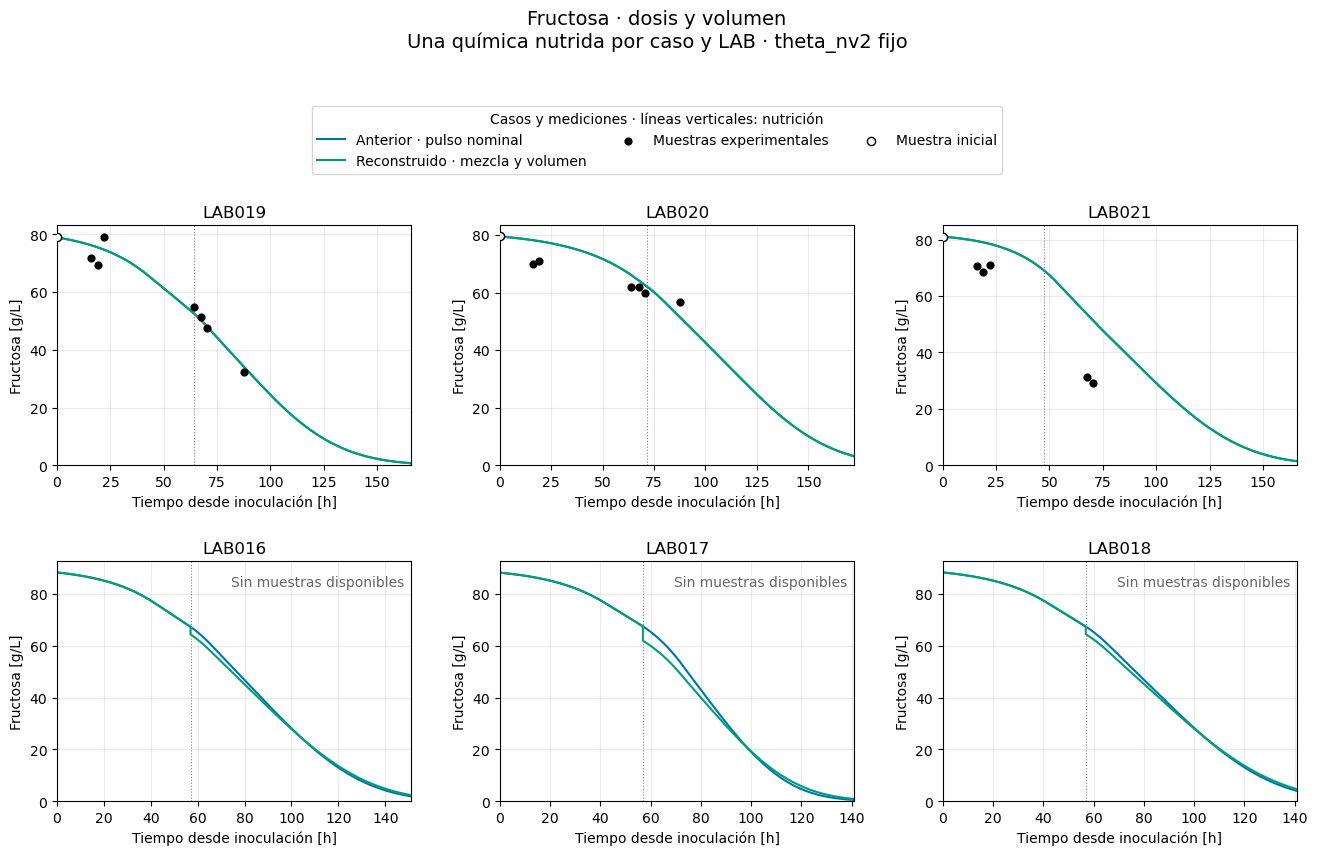

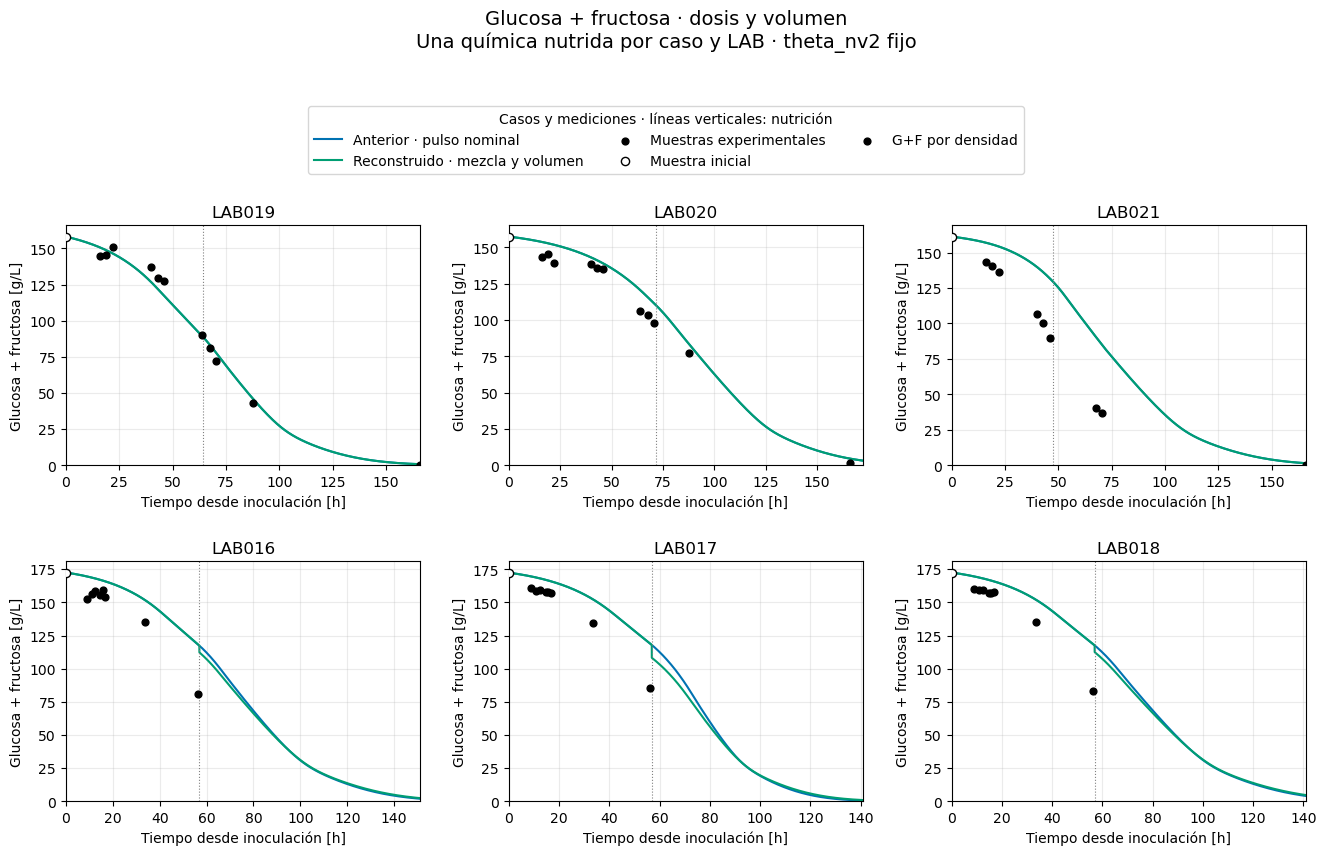

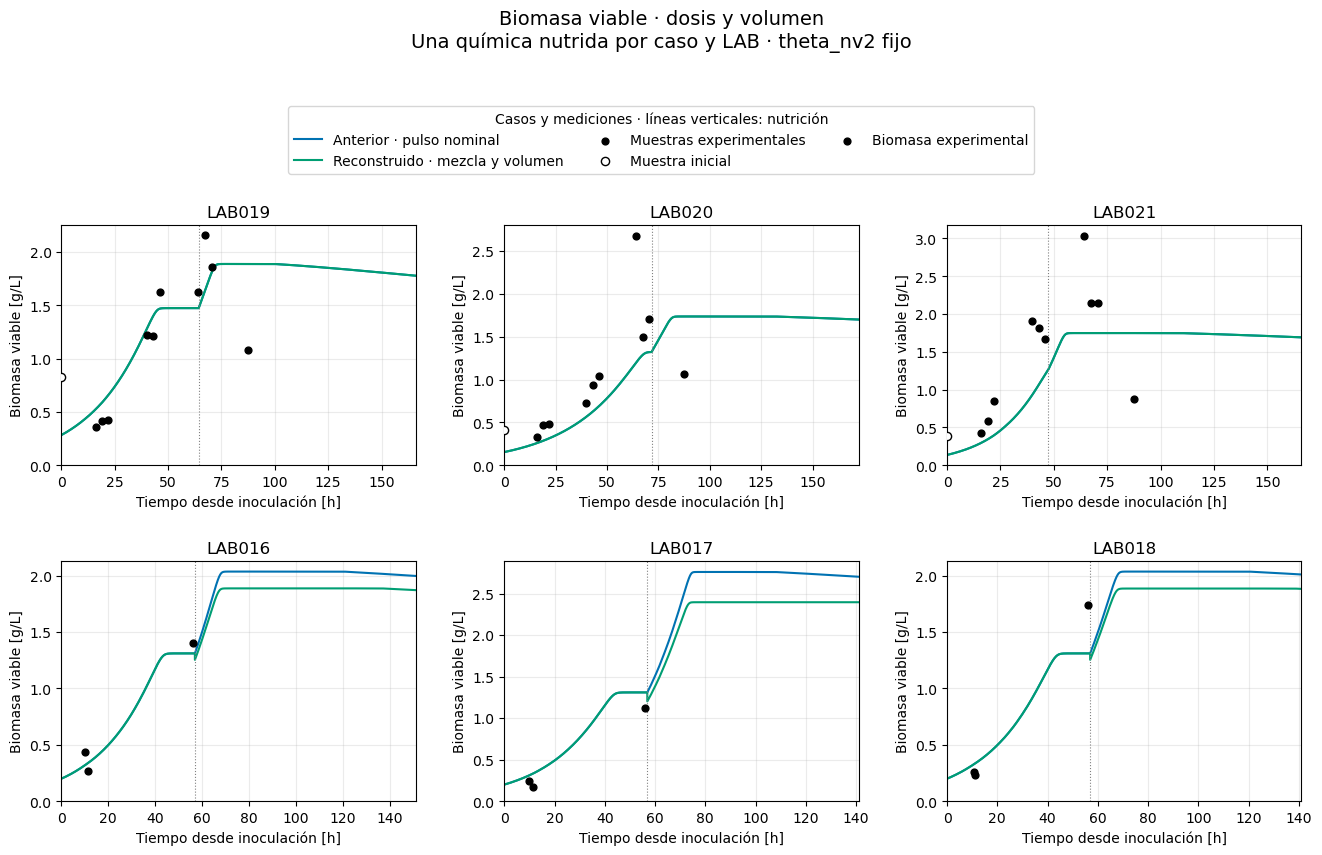

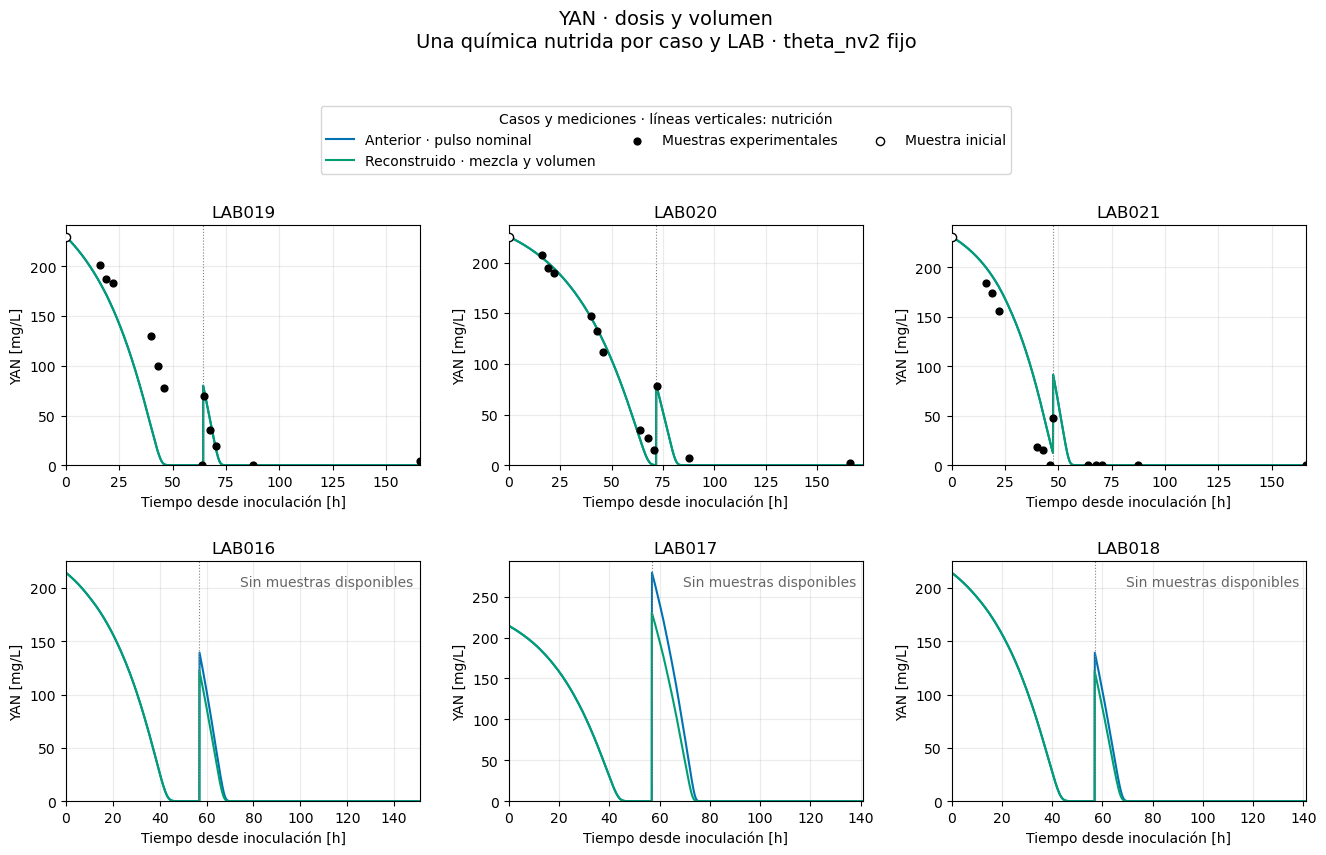

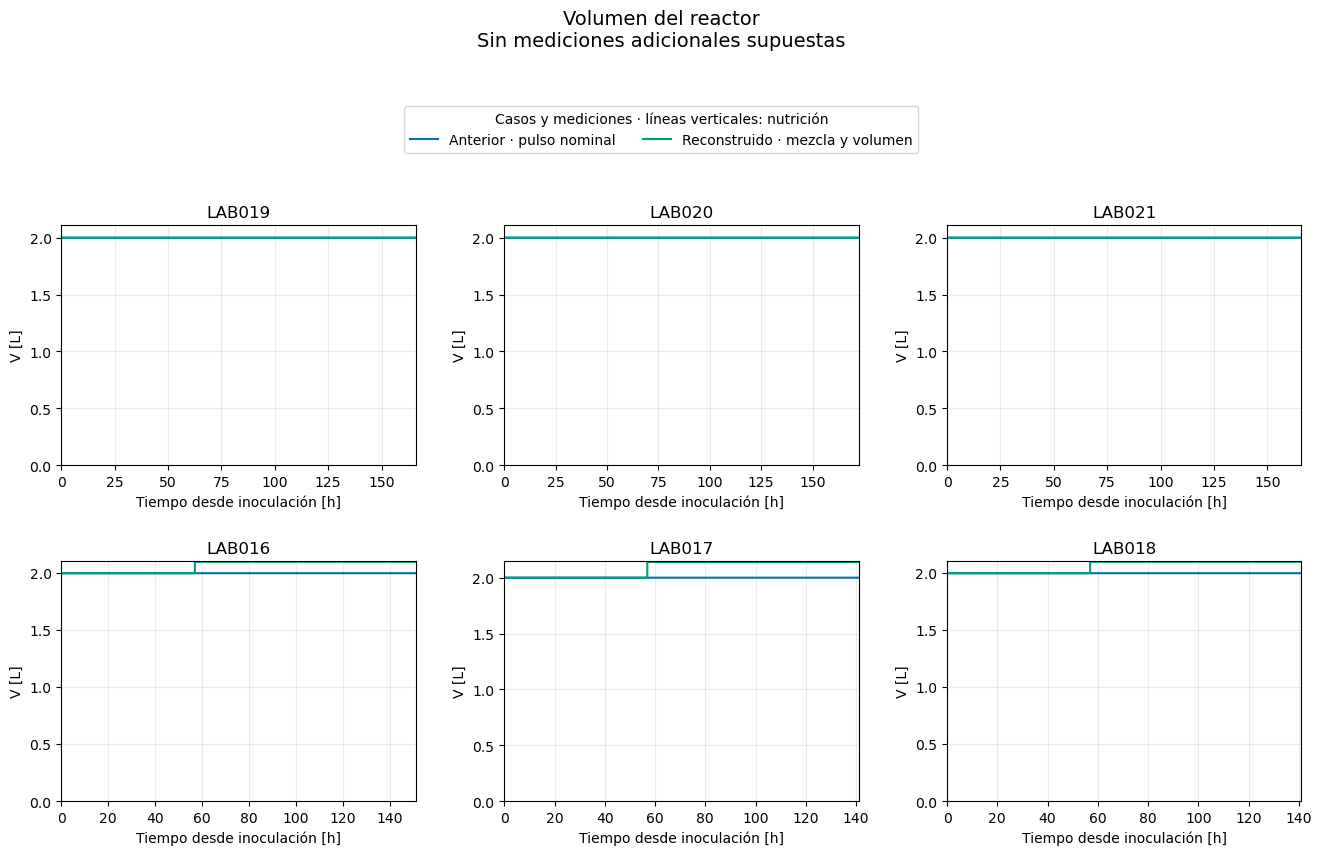

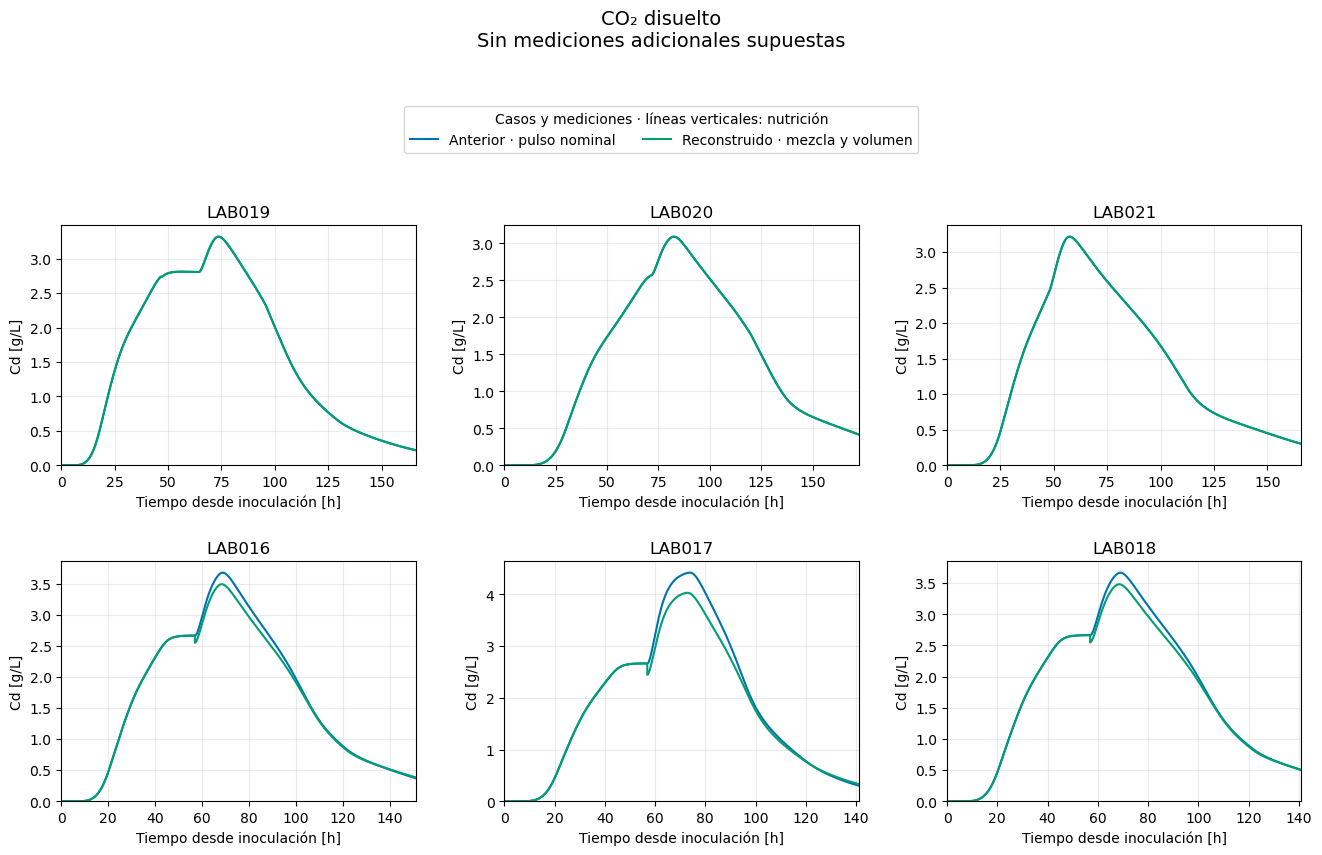

In [4]:
def finish(fig,axes,title,subtitle):
 items={}
 for ax in axes.flat:
  hh,ll=ax.get_legend_handles_labels()
  for h,l in zip(hh,ll):items.setdefault(l,h)
 fig.suptitle(title+'\n'+subtitle,y=.99,fontsize=14)
 fig.legend(items.values(),items.keys(),loc='upper center',bbox_to_anchor=(.5,.89),ncol=3,title='Casos y mediciones · líneas verticales: nutrición')
 fig.subplots_adjust(top=.75,hspace=.4,wspace=.25);plt.show()
for window in ['Registro','Pico posterior','Cola tardía','Referencia2L']:
 fig,axes=plt.subplots(2,3,figsize=(16,9))
 for ax,lab in zip(axes.flat,LABS):
  start,end=windows[lab]['Registro' if window=='Referencia2L' else window]
  o=observed_common[lab];o=o.loc[o.time_h.between(start,end)]
  yy=o.co2_raw_g_l_h if window=='Referencia2L' else o.y_common
  ax.plot(o.time_h,yy,color='black',lw=1.1,label='Medianas horarias del sensor')
  for case in CASES:
   f=gascurves[case,lab];m=(f.index>=start)&(f.index<=end)
   vals=gas_values(case,lab,f.index,f)
   if window=='Referencia2L':vals=vals/factor(lab,f.index)
   ax.plot(f.index[m],vals[m],color=COLORS[case],label=case)
  for event,d in batches[lab].pulses['N']:
   if start<=event<=end:ax.axvline(event,color='.5',ls=':',lw=.8)
  ax.set(title=lab+(' · Comparación sin cambios' if lab in LABS[:3] else ' · Reconstrucción de alimentación'),
   xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ [g/(L·h)]' if window!='Referencia2L' else 'CO₂ [g/(Lref·h)], Lref=2L',xlim=(start,end))
  ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 finish(fig,axes,'CO₂ · '+window,'Dosis, mezcla y volumen reconstruidos · parámetros congelados')
for key,title,scale,unit in CHEM:
 fig,axes=plt.subplots(2,3,figsize=(16,9))
 for ax,lab in zip(axes.flat,LABS):
  for case in CASES:
   f=chemistry[case,lab];ax.plot(f.index,f[key]*scale,color=COLORS[case],label=case)
  t,z,label=samples(lab,key);ini=t==0
  if len(t):
   ax.scatter(t[~ini],z[~ini]*scale,color='black',s=24,zorder=5,label=label)
   if ini.any():ax.scatter(t[ini],z[ini]*scale,facecolors='white',edgecolors='black',s=35,zorder=6,label='Muestra inicial')
  else:ax.text(.98,.94,label,ha='right',va='top',transform=ax.transAxes,color='.4')
  for event,d in batches[lab].pulses['N']:ax.axvline(event,color='.5',ls=':',lw=.8)
  ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel=title+' ['+unit+']',
   xlim=(0,max(v.horizons[lab],t.max() if len(t) else 0)));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 finish(fig,axes,title+' · dosis y volumen','Una química nutrida por caso y LAB · theta_nv2 fijo')
for key,title in [('V','Volumen del reactor'),('Cd','CO₂ disuelto')]:
 fig,axes=plt.subplots(2,3,figsize=(16,9))
 for ax,lab in zip(axes.flat,LABS):
  for case in CASES:
   f=gascurves[case,lab];tt=f.index
   yy=(np.full(len(tt),2.) if case==CASES[0] else volume(lab,tt)) if key=='V' else f.Cd
   ax.plot(tt,yy,color=COLORS[case],label=case)
  ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel='V [L]' if key=='V' else 'Cd [g/L]',xlim=(0,v.horizons[lab]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 finish(fig,axes,title,'Sin mediciones adicionales supuestas')


In [5]:
assert theta==theta_before
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in before.items())
for lab in LABS[:3]:
 pd.testing.assert_frame_equal(chemistry[CASES[0],lab],chemistry[CASES[1],lab])
 pd.testing.assert_frame_equal(gascurves[CASES[0],lab],gascurves[CASES[1],lab])
print('Verificado: RHS y todos los parámetros originales intactos; sin optimización ni core0.')
print('Sólo se modifican en memoria alimentación, dilución y volumen de016–018; balance global de mezcla verificado.')
print('SUMMARY_JSON')
print(metrics.groupby(['tramo','rol','caso']).RMSE.mean().reset_index().to_json(orient='records',force_ascii=False))

assert all(batches[l].initials['X']==.20 for l in GROUP)
assert all(batches[l].initials==initials_before[l] for l in LABS[:3])


Verificado: RHS y todos los parámetros originales intactos; sin optimización ni core0.
Sólo se modifican en memoria alimentación, dilución y volumen de016–018; balance global de mezcla verificado.
SUMMARY_JSON
[{"tramo":"Cola tardía","rol":"Calibración previa","caso":"Anterior · pulso nominal","RMSE":0.0977670327},{"tramo":"Cola tardía","rol":"Calibración previa","caso":"Reconstruido · mezcla y volumen","RMSE":0.0977670327},{"tramo":"Cola tardía","rol":"Holdout previo","caso":"Anterior · pulso nominal","RMSE":0.0502568282},{"tramo":"Cola tardía","rol":"Holdout previo","caso":"Reconstruido · mezcla y volumen","RMSE":0.0459875829},{"tramo":"Pico posterior","rol":"Calibración previa","caso":"Anterior · pulso nominal","RMSE":0.1223966852},{"tramo":"Pico posterior","rol":"Calibración previa","caso":"Reconstruido · mezcla y volumen","RMSE":0.1223966852},{"tramo":"Pico posterior","rol":"Holdout previo","caso":"Anterior · pulso nominal","RMSE":0.1951995778},{"tramo":"Pico posterior","rol":"Hol

## Resultado con X0=0.20 g/L en LAB016–018

Se rehízo el MISMO notebook15. X0=0.20g/L (6.6667 millones de células viables/mL, redondeado6.67) se aplica tanto al nominal como al reconstruido. LAB019–021 conservan todas sus iniciales y reproducen el error medio previo0.1280027902. No se recalibró theta_nv2 ni ningún coeficiente.

La comparación azul/verde sigue identificando pulso nominal frente a dosis/mezcla/volumen reconstruidos, ahora con la misma X0=0.20 en ambos. No representa X0=0.39 frente a0.20 en las figuras. Se recalculan química, consumoO₂, Cd y composición del mosto retornado con la nueva biomasa. Las masas de YAN externo y volúmenes no se vuelven a ajustar.

### Comparación de casos con la nueva inicialización

RMSE ordinario medio de CO₂ en LAB016–018, g/(L·h), con predicciones y observaciones normalizadas al mismo volumen reconstruido:

| Tramo | Nominal con X0=0.20 | Reconstruido con X0=0.20 |
|---|---:|---:|
| Registro completo | 0.143358 | 0.134295 |
| Primeras24h después del pulso | 0.195200 | 0.165350 |
| Cola desde32h tras el pulso | 0.050257 | 0.045988 |

### Contexto respecto a la ejecución reemplazada

Para el caso reconstruido, la ejecución previa con X0=0.39 tenía RMSE medio0.122861 en registro,0.180820 en pico y0.064964 en cola. Con X0=0.20 pasan a0.134295,0.165350 y0.045988. La cola y la ventana del pico mejoran en ese promedio, pero el registro completo empeora; no se afirma mejora global ni que0.20 sea la biomasa experimental verdadera. Las cifras previas se conservan como contexto, no se añaden curvas simuladas de X0=0.39 a las figuras de esta ejecución.

Persisten diferencias en la forma y cronología del CO₂. Las muestras disponibles de016–018 son anteriores al pulso y no validan directamente la química postnutrición. Se conservan todas las muestras por variable; G+F por densidad no se reparte entre glucosa y fructosa.

### Reconstrucción y límites que permanecen fijos

Retorno59.574mL, agua inicial500mL, dosis objetivo140mg/L sobre2L previos, mezclado homogéneo y posterior200mL a017. Aportes de nutriente externo por2L:128.408/246.678/128.097mg/L; volumen final2.1/2.140426/2.1L. El YAN químico postmezcla se calcula con masa, volumen y YAN residual del nuevo core, no se impone artificialmente un valor final.

La operación se representa como salto en el horario nominal, sin resolver los715s de alimentación biológica continua ni desgasificación/reacción del pulmón; Cd/O₂ iniciales del agua se suponen cero. Se comprueban balances globales de X,N,G,F,E,Cd,O₂ incluyendo pulmón remanente y balance de Cd entre saltos. Las correcciones de observación son sólo en memoria, iguales para ambos casos. La figura Referencia2L permite revisar el caudal en la referencia previa.

Los archivos de datos, iniciales guardadas, modelos, parámetros y notebooks restantes permanecen intactos. Los únicos artefactos científicos reemplazados son SOURCE y EXECUTED del15. Sin CSV/PNG de resultados, commit ni push.
